# 05 Career profiles

Phases 2 to 4 compared seasons: a player's comps were the players whose single best-matching season was closest to one of his. That rewards one-off matches and ignores the shape of a career. Phase 5 builds one profile per player from his season embeddings (the Phase 4 model: the Phase 3 encoder with season centring at alpha 0.5) and compares whole careers.

A profile has three parts. The **centre** is the minutes-weighted average of a player's season embeddings, the typical version of him. The **peak** is the average of his top 3 seasons by BPM (BPM only picks which seasons count as the peak; it never enters a similarity). The **spread** is the minutes-weighted mean cosine distance of his seasons from his centre: low means consistent, high means his seasons differ a lot. The career score combines centre and peak similarity, with an optional lambda penalty on the difference in spread.

This notebook **only reads**. It trains nothing and writes nothing under `reports/` or `models/`: it rebuilds profiles from the saved Phase 4 weights and reads `reports/phase5_search.csv`. Numbers are on the **validation** split, which also chose the method, so they are optimistic. The test split and the five hold-outs are never touched.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from career import BestSeasonMatch, CareerScore, top_k
from evaluate import SANITY
from evaluate_career import (LAMBDAS, SEARCH_CSV, SHAPE_PLAYERS, build_method, choose, seed_data, splits)

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 150)
df, train, val, _, pool = splits()
search = pd.read_csv(SEARCH_CSV)
report_text = (ROOT / "reports" / "phase5_career.md").read_text()

keys = ["method", "alpha", "beta", "lambda", "name"]
agg = search.groupby(keys, dropna=False).agg(
    split_half_hit10=("split_half_hit10", "mean"), split_half_mrr=("split_half_mrr", "mean"),
    cross_era=("cross_era", "mean"), spread_gap=("spread_gap", "mean")).reset_index()
best = choose(agg)
print(f"{len(search)} search rows. Chosen: {best['name']}")

# seed 2026 profiles: the Phase 4 model (centring alpha 0.5 on the lambda 0 encoder), built from saved weights
model, scale, val_profs, _, pool_profs = seed_data(2026, df, train, val, pool)
by_id = {p.player_id: i for i, p in enumerate(pool_profs)}
chosen = build_method(best, scale)
long_career = [p for p in pool_profs if len(p.emb) >= 4]
spreads = np.array([p.spread for p in long_career])
print(f"{len(pool_profs)} pool players with 2+ seasons, {len(long_career)} with 4+ seasons")

66 search rows. Chosen: Career a=0.25 b=0.75 lambda=0.0


2012 pool players with 2+ seasons, 1489 with 4+ seasons


## 1. Profiles

For three players, each season's cosine distance from his own centre, over his career. The dashed line is his spread (the minutes-weighted mean of those distances). Stockton is the picture of consistency; Rodman's seasons wander more.

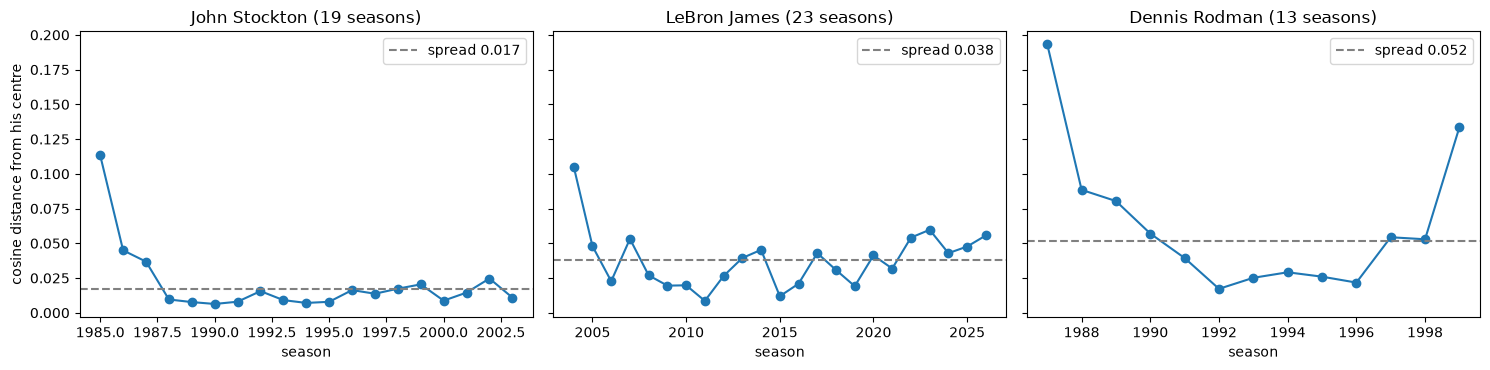

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, pid in zip(axes, ["stockjo01", "jamesle01", "rodmade01"]):
    p = pool_profs[by_id[pid]]
    dist = 1 - p.emb @ p.centre
    ax.plot(p.seasons, dist, marker="o")
    ax.axhline(p.spread, c="grey", ls="--", label=f"spread {p.spread:.3f}")
    ax.set(title=f"{p.player} ({len(p.seasons)} seasons)", xlabel="season")
    ax.legend()
axes[0].set_ylabel("cosine distance from his centre")
plt.tight_layout(); plt.show()

## 2. Spread distribution

Spread of every pool player with 4 or more qualified seasons, with the five shape players marked. The percentile is the share of those players with a lower (more consistent) spread. The feature note's test: Stockton should be consistent.

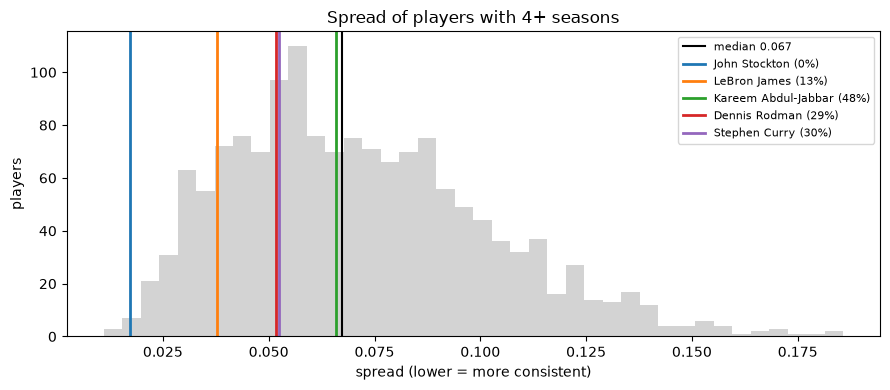

,seasons,spread,percentile
player,,,
John Stockton,19,0.0173,0%
LeBron James,23,0.0379,13%
Kareem Abdul-Jabbar,10,0.0658,48%
Dennis Rodman,13,0.0516,29%
Stephen Curry,16,0.0524,30%


Matches reports/phase5_career.md


In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(spreads, bins=40, color="lightgrey")
ax.axvline(np.median(spreads), c="black", label=f"median {np.median(spreads):.3f}")
rows = []
for k, (pid, name) in enumerate(SHAPE_PLAYERS.items()):
    p = pool_profs[by_id[pid]]
    pct = float((spreads < p.spread).mean())
    ax.axvline(p.spread, c=f"C{k}", lw=2, label=f"{name} ({pct:.0%})")
    rows.append({"player": name, "seasons": len(p.emb), "spread": round(p.spread, 4), "percentile": f"{pct:.0%}"})
ax.set(xlabel="spread (lower = more consistent)", ylabel="players", title="Spread of players with 4+ seasons")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
shape = pd.DataFrame(rows).set_index("player"); display(shape)
for r in rows:
    assert f"| {r['player']} | {r['seasons']} | {r['spread']:.4f} | {r['percentile']} |" in report_text, f"disagrees with report: {r}"
print("Matches reports/phase5_career.md")

## 3. The search

20 career-score settings (5 centre/peak weightings x 4 lambdas), plus Wasserstein (optimal transport over the full season sets) and the best-season reference, each scored on split-half identity retrieval: every validation player with 4+ seasons is split into two pseudo-players (alternating seasons), and a hit means one half finds the other in its top 10. Mean over 3 seeds. Left: the career-score settings. Right: hit@10 against lambda, with Wasserstein and best-season as reference lines.

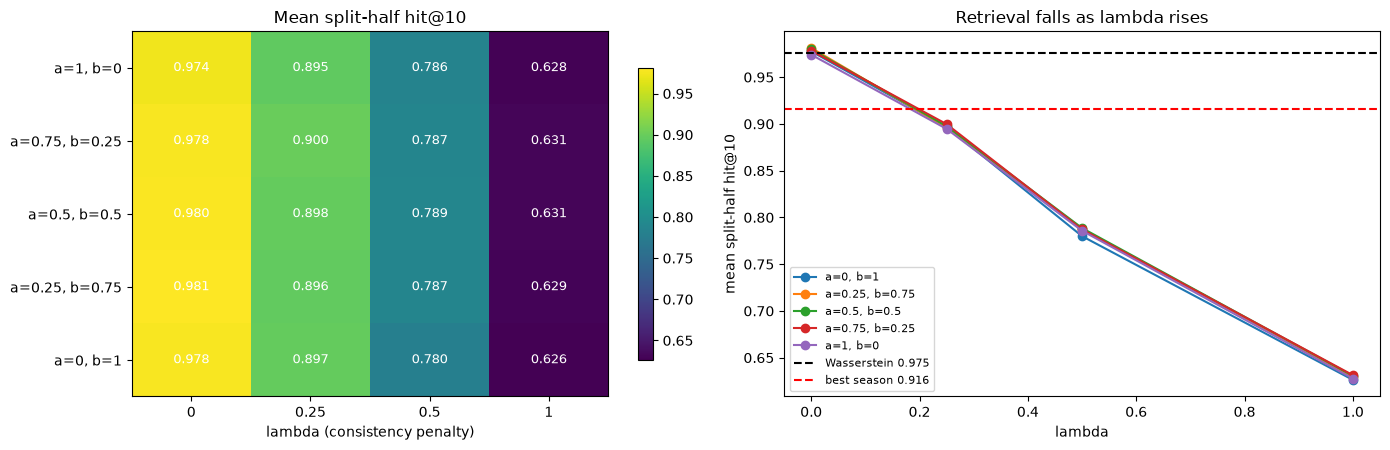

Best at lambda 0 for every weighting beats best-season (0.916): True


,name,split_half_hit10,split_half_mrr,cross_era,spread_gap
Chosen,Career a=0.25 b=0.75 lambda=0.0,0.981,0.900,0.748,0.029
Centre only,Career a=1.0 b=0.0 lambda=0.0,0.974,0.909,0.738,0.029
Wasserstein,"Wasserstein (Sinkhorn, eps 0.05)",0.975,0.896,0.734,0.027
Best season,Best season match,0.916,0.695,0.720,0.030


Mean split-half hit@10 for the chosen weights at each lambda: {0.0: 0.981, 0.25: 0.896, 0.5: 0.787, 1.0: 0.629}
Matches reports/phase5_career.md


In [4]:
car = agg[agg["method"] == "career"]
heat = car.pivot_table(index=["alpha", "beta"], columns="lambda", values="split_half_hit10").sort_index(ascending=False)
wass = agg[agg["method"] == "wasserstein"]["split_half_hit10"].iloc[0]
ref = agg[agg["method"] == "best_season"]["split_half_hit10"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
im = axes[0].imshow(heat.to_numpy(), cmap="viridis", aspect="auto")
axes[0].set_xticks(range(len(heat.columns)), [f"{c:g}" for c in heat.columns])
axes[0].set_yticks(range(len(heat.index)), [f"a={a:g}, b={b:g}" for a, b in heat.index])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        axes[0].text(j, i, f"{heat.iat[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
axes[0].set(xlabel="lambda (consistency penalty)", title="Mean split-half hit@10"); fig.colorbar(im, ax=axes[0], shrink=0.8)

for (a, b), g in car.groupby(["alpha", "beta"]):
    axes[1].plot(g["lambda"], g["split_half_hit10"], marker="o", label=f"a={a:g}, b={b:g}")
axes[1].axhline(wass, c="black", ls="--", label=f"Wasserstein {wass:.3f}")
axes[1].axhline(ref, c="red", ls="--", label=f"best season {ref:.3f}")
axes[1].set(xlabel="lambda", ylabel="mean split-half hit@10", title="Retrieval falls as lambda rises"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Best at lambda 0 for every weighting beats best-season ({ref:.3f}): "
      f"{bool((car[car['lambda'] == 0]['split_half_hit10'] > ref).all())}")
centre_only = agg[(agg["method"] == "career") & (agg["alpha"] == 1.0) & (agg["lambda"] == 0.0)].iloc[0]
ref_row = agg[agg["method"] == "best_season"].iloc[0]
cmp = pd.DataFrame([best, centre_only, agg[agg["method"] == "wasserstein"].iloc[0], ref_row])
cmp.index = ["Chosen", "Centre only", "Wasserstein", "Best season"]
display(cmp[["name", "split_half_hit10", "split_half_mrr", "cross_era", "spread_gap"]].round(3))
print("Mean split-half hit@10 for the chosen weights at each lambda:",
      car[(car["alpha"] == best["alpha"]) & (car["beta"] == best["beta"])].set_index("lambda")["split_half_hit10"].round(3).to_dict())
for lab, r in [("Chosen", best), ("Centre only (alpha 1, lambda 0)", centre_only), ("Best season match (Phases 2 to 4 reference)", ref_row)]:
    line = f"| {lab}" if lab == "Chosen" else f"| {lab} | {r['split_half_hit10']:.3f}"
    assert line in report_text or lab == "Chosen", f"disagrees with report: {lab}"
assert f"| {best['cross_era']:.3f} |" in report_text
print("Matches reports/phase5_career.md")

## 4. The lambda slider

For the chosen weights, validation players, seed 2026: as lambda rises, the top 10 comps get closer in spread (the consistency preference at work) and drift away from the lambda 0 list. The table shows Stockton's top 5 at each lambda, with each comp's spread in brackets. Lambda is a preference slider ("show me careers shaped like his"), not an accuracy knob: split-half retrieval falls as it rises (section 3).

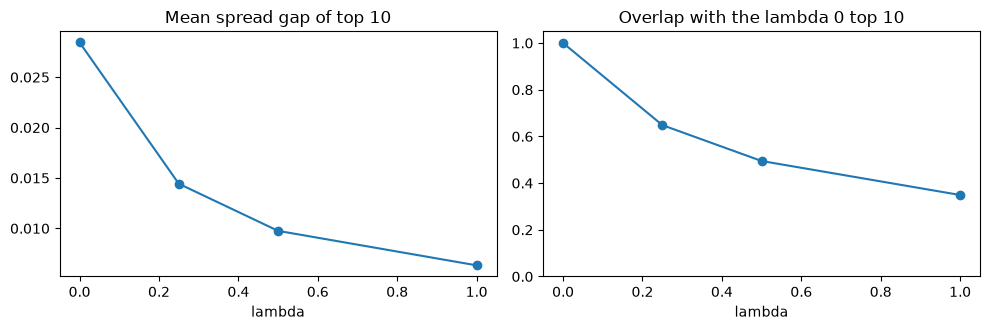

,mean spread gap,overlap with lambda 0,Stockton's top 5 (spread)
lambda,,,
0.00,0.0284,100%,"Chris Paul (0.039), Kevin Porter (0.005), Micheal Williams (0.022), Maurice Cheeks (0.029), Kevin Johnson (0.031)"
0.25,0.0144,65%,"Micheal Williams (0.022), Kevin Porter (0.005), Maurice Cheeks (0.029), Chris Paul (0.039), Brevin Knight (0.028)"
0.50,0.0098,49%,"Micheal Williams (0.022), Kevin Porter (0.005), Keith Jennings (0.014), Maurice Cheeks (0.029), Raül López (0.018)"
1.00,0.0063,35%,"Micheal Williams (0.022), Raül López (0.018), Isaiah Collier (0.017), Keith Jennings (0.014), Othell Wilson (0.018)"


Spread of John Stockton himself: 0.017
Matches reports/phase5_career.md


In [5]:
gaps, overlaps, stockton, base = [], [], {}, None
for lam in LAMBDAS:
    m = CareerScore(best["alpha"], best["beta"], lam, scale)
    tops = top_k(m, val_profs, val_profs, 10)
    gaps.append(np.mean([np.mean([abs(val_profs[j].spread - p.spread) for j in t]) for p, t in zip(val_profs, tops)]))
    base = tops if base is None else base
    overlaps.append(np.mean([len(set(a) & set(b)) / 10 for a, b in zip(tops, base)]))
    st = top_k(m, [pool_profs[by_id["stockjo01"]]], pool_profs, 5)[0]
    stockton[lam] = ", ".join(f"{pool_profs[j].player} ({pool_profs[j].spread:.3f})" for j in st)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(LAMBDAS, gaps, marker="o"); axes[0].set(title="Mean spread gap of top 10", xlabel="lambda")
axes[1].plot(LAMBDAS, overlaps, marker="o"); axes[1].set(title="Overlap with the lambda 0 top 10", xlabel="lambda", ylim=(0, 1.05))
plt.tight_layout(); plt.show()
slider = pd.DataFrame({"mean spread gap": np.round(gaps, 4), "overlap with lambda 0": [f"{o:.0%}" for o in overlaps],
                       "Stockton's top 5 (spread)": [stockton[l] for l in LAMBDAS]}, index=pd.Index(LAMBDAS, name="lambda"))
display(slider)
print(f"Spread of John Stockton himself: {pool_profs[by_id['stockjo01']].spread:.3f}")
for lam, g, o in zip(LAMBDAS, gaps, overlaps):
    assert f"| {lam} | {g:.4f} | {o:.0%} |" in report_text, f"lambda row disagrees with report: {lam}"
print("Matches reports/phase5_career.md")

## 5. Career comps vs season comps

Top 5 comp players (whole careers, hold-outs excluded from the pool, seed 2026) under the chosen career method, next to the Phases 2 to 4 best-season matching on the same season embeddings. The year is each comp's first qualified season.

In [6]:
by_name = {v: k for k, v in SANITY.items()}
rows = []
for name in ["Michael Jordan", "Charles Barkley", "Steve Nash", "Nikola Jokić"]:
    q = [pool_profs[by_id[by_name[name]]]]
    for label, m in [("Career (chosen)", chosen), ("Best season", BestSeasonMatch())]:
        t = top_k(m, q, pool_profs, 5)[0]
        rows.append({"player": name, "method": label, "top 5": ", ".join(f"{pool_profs[j].player} {pool_profs[j].seasons.min()}" for j in t)})
pd.DataFrame(rows).set_index(["player", "method"])

top 5
player          method                                                                                                                      
Michael Jordan  Career (chosen)  Kobe Bryant 1997, Dwyane Wade 2004, Shai Gilgeous-Alexander 2019, Donovan Mitchell 2018, Kawhi Leonard 2012
                Best season                 LeBron James 2004, Kobe Bryant 1997, Tracy McGrady 1998, Dominique Wilkins 1983, Grant Hill 1995
Charles Barkley Career (chosen)                   Karl Malone 1986, Nikola Jokić 2016, Jeff Ruland 1982, Shawn Kemp 1990, Kevin Garnett 1996
                Best season                  Kevin Garnett 1996, Karl Malone 1986, Paul Millsap 2007, Shawn Kemp 1990, Domantas Sabonis 2017
Steve Nash      Career (chosen)             José Calderón 2006, Mark Price 1987, Kenny Smith 1988, Tyrese Haliburton 2021, Scott Skiles 1988
                Best season                     Jordan Farmar 2007, Kirk Hinrich 2004, Mark Price 1987, Steve Blake 2004, José Calderón 2006
Nikola Jokić    Career (chosen)          Kevin Garnett 1996, Charles Barkley 1985, Karl Malone 1986, DeMarcus Cousins 2011, Joel Embiid 2017
                Best season              Kevin Garnett 1996, Arvydas Sabonis 1996, Greg Monroe 2011, Domantas Sabonis 2017, Karl Malone 1986

## 6. Findings

- **Career profiles recognise a player better than best-season matching.** Split-half hit@10 is 0.981 for the chosen setting (centre weight 0.25, peak weight 0.75, lambda 0) against 0.916 for best-season matching, and every lambda 0 setting beats it (section 3). MRR is 0.900 against 0.695.
- **Peak helps a little.** The chosen weights beat centre only on hit@10 (0.981 against 0.974), but centre only has the higher MRR (0.909 against 0.900), so the weightings are close.
- **Lambda behaves as a preference slider.** Raising it pulls the top 10 comps toward the query's spread (mean spread gap 0.0284, 0.0144, 0.0098, 0.0063 at lambda 0, 0.25, 0.5, 1.0) and shrinks the overlap with the lambda 0 list to 100%, 65%, 49% and 35% (section 4). It costs identity retrieval: mean split-half hit@10 falls from 0.981 to 0.629 across the grid, so lambda 0 is chosen on accuracy.
- **Career shape matches the feature note.** John Stockton has the lowest spread of any pool player with 4+ seasons (0th percentile), LeBron is at the 13th percentile, Rodman the 29th, Curry the 30th and Kareem the 48th (section 2).
- **Comps cross eras a little more.** The cross-era share of top-10 career comps is 0.748 for the chosen method against 0.720 for best-season matching (section 3).
- **Caveat:** these are validation numbers that also chose the method, so they are optimistic. The new sanity comps are unmarked, so there is no sanity verdict yet.